# Indian Sign Language (ISL) Alphabet Classification 

In [1]:
import os, zipfile, random, warnings, json, math
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

import cv2

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Python/TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

Python/TensorFlow: 2.19.0
NumPy: 2.4.6
OpenCV: 5.0.0
GPU devices: []


In [ ]:

DATASET_DIR = Path("ISL_Dataset")

ZIP_PATH = Path("ISL_Dataset.zip")

if not DATASET_DIR.exists() and ZIP_PATH.exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(".")
    print("Extracted:", ZIP_PATH)

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Could not find {DATASET_DIR.resolve()}. "
        "Extract ISL_Dataset.zip beside this notebook or update DATASET_DIR."
    )

print("Dataset directory:", DATASET_DIR.resolve())

Dataset directory: C:\Users\Dell\Downloads\CNN practice\ISL_Dataset


In [3]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_dirs = sorted(
    [p for p in DATASET_DIR.iterdir() if p.is_dir() and p.name.strip()],
    key=lambda p: p.name.upper()
)

class_names = [p.name.strip().upper() for p in class_dirs]
if not class_dirs:
    raise ValueError("No class folders found inside the dataset directory.")

image_paths, image_labels = [], []
for folder in class_dirs:
    for path in sorted(folder.rglob("*")):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTS:
            image_paths.append(path)
            image_labels.append(folder.name.strip().upper())

counts = pd.Series(image_labels).value_counts().sort_index()
count_table = pd.DataFrame({"class": counts.index, "image_count": counts.values})
display(count_table)
print("Total images:", len(image_paths))
print("Detected classes:", len(counts))
print("Class names:", sorted(counts.index.tolist()))

,class,image_count
0,A,25
1,B,38
2,C,34
3,D,34
4,E,46
5,F,21
6,G,29
7,I,30
8,K,36
9,L,36


Total images: 702
Detected classes: 23
Class names: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Z']


In [4]:
# Inspect image dimensions, color modes, and unreadable files.
dimension_counts, mode_counts, unreadable = Counter(), Counter(), []
for path in image_paths:
    try:
        with Image.open(path) as im:
            dimension_counts[im.size] += 1
            mode_counts[im.mode] += 1
    except Exception as exc:
        unreadable.append((str(path), str(exc)))

print("Most common dimensions:", dimension_counts.most_common(10))
print("Color modes:", mode_counts)
print("Unreadable images:", len(unreadable))
if unreadable:
    display(pd.DataFrame(unreadable, columns=["path", "error"]).head())

Most common dimensions: [((128, 128), 702)]
Color modes: Counter({'RGB': 702})
Unreadable images: 0


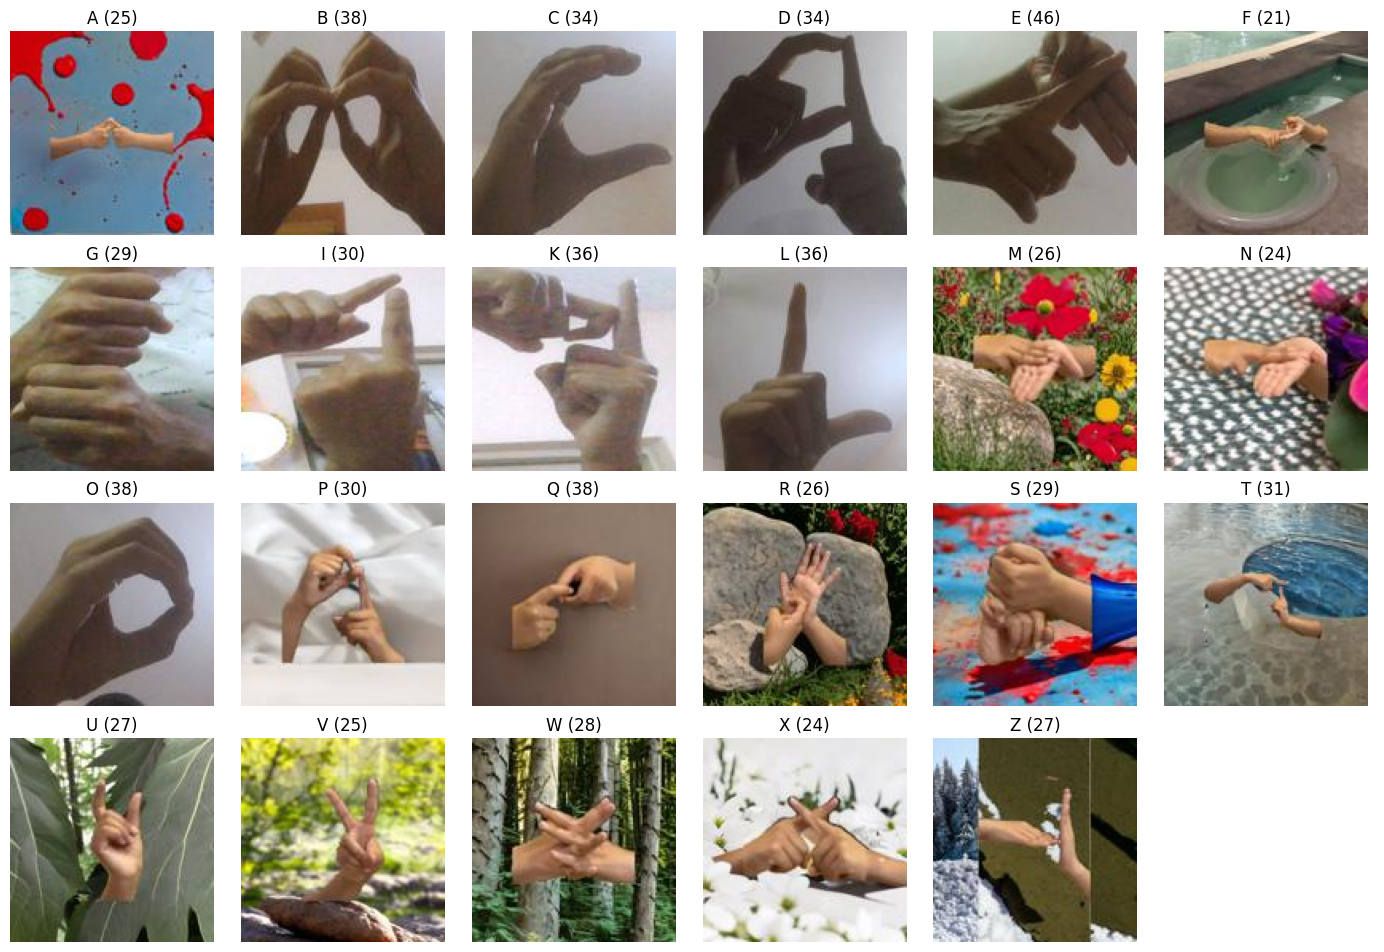

In [5]:
n_classes = len(class_names)
cols = 6
rows = math.ceil(n_classes / cols)
fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 2.4))
axes = np.array(axes).reshape(-1)

for ax, cls in zip(axes, class_names):
    candidates = [p for p, lab in zip(image_paths, image_labels) if lab == cls]
    if candidates:
        with Image.open(candidates[0]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"{cls} ({len(candidates)})")
    ax.axis("off")

for ax in axes[len(class_names):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
IMG_HEIGHT = 64
IMG_WIDTH = 64
CHANNELS = 3

# Sort class labels consistently and create an index mapping.
class_names = sorted(set(image_labels))
class_to_index = {name: idx for idx, name in enumerate(class_names)}
index_to_class = {idx: name for name, idx in class_to_index.items()}

X_list, y_list, valid_paths = [], [], []
failed = []

for path, label in zip(image_paths, image_labels):
    try:
        with Image.open(path) as im:
            im = im.convert("RGB").resize((IMG_WIDTH, IMG_HEIGHT), Image.Resampling.LANCZOS)
            arr = np.asarray(im, dtype=np.float32) / 255.0
        X_list.append(arr)
        y_list.append(class_to_index[label])
        valid_paths.append(str(path))
    except Exception as exc:
        failed.append((str(path), str(exc)))

X = np.stack(X_list)
y = np.asarray(y_list, dtype=np.int64)

print("X shape:", X.shape)  # (number_of_images, 64, 64, 3)
print("y shape:", y.shape)
print("Classes:", class_names)
print("Number of classes:", len(class_names))
print("Failed files:", len(failed))

X shape: (702, 64, 64, 3)
y shape: (702,)
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Z']
Number of classes: 23
Failed files: 0


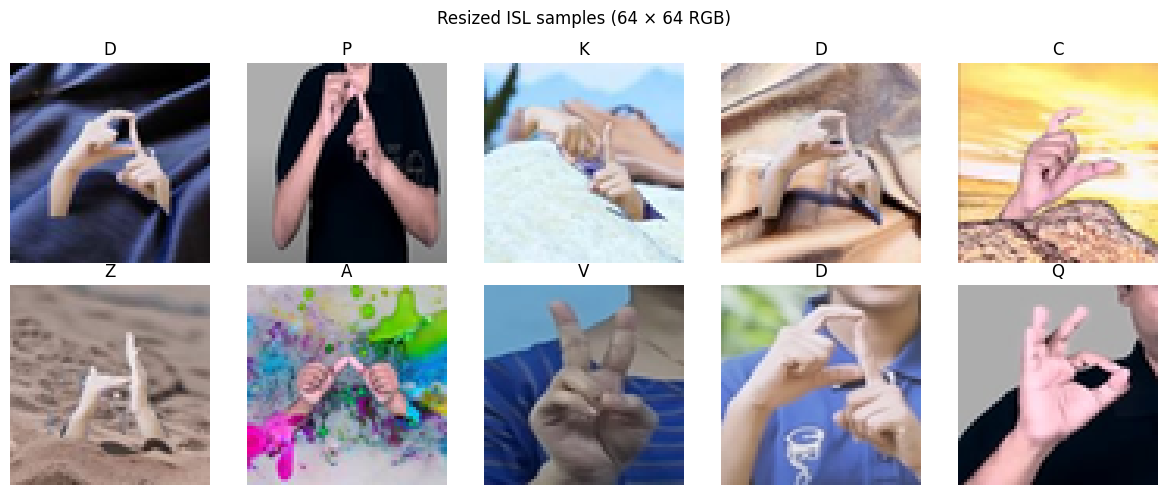

In [7]:
# Display a few resized images and verify labels.
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.ravel()):
    idx = np.random.randint(0, len(X))
    ax.imshow(X[idx])
    ax.set_title(class_names[y[idx]])
    ax.axis("off")
plt.suptitle("Resized ISL samples (64 × 64 RGB)")
plt.tight_layout()
plt.show()

##  Split into training, validation and test sets


In [8]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1765,
    random_state=SEED, stratify=y_train_full
)

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

split_counts = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(),
    "validation": pd.Series(y_val).value_counts(),
    "test": pd.Series(y_test).value_counts()
}).fillna(0).astype(int).sort_index()
split_counts.index = [index_to_class[i] for i in split_counts.index]
display(split_counts)

Train: (490, 64, 64, 3) Validation: (106, 64, 64, 3) Test: (106, 64, 64, 3)


,train,validation,test
A,17,4,4
B,26,6,6
C,24,5,5
D,24,5,5
E,32,7,7
F,15,3,3
G,21,4,4
I,21,4,5
K,26,5,5
L,26,5,5


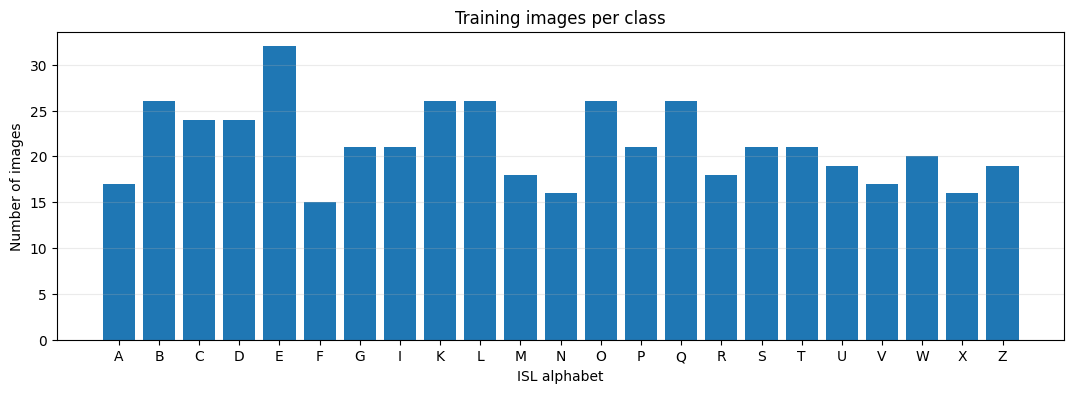

Class weights: {0: 1.2531969309462916, 1: 0.8193979933110368, 2: 0.8876811594202898, 3: 0.8876811594202898, 4: 0.6657608695652174, 5: 1.4202898550724639, 6: 1.0144927536231885, 7: 1.0144927536231885, 8: 0.8193979933110368, 9: 0.8193979933110368, 10: 1.183574879227053, 11: 1.3315217391304348, 12: 0.8193979933110368, 13: 1.0144927536231885, 14: 0.8193979933110368, 15: 1.183574879227053, 16: 1.0144927536231885, 17: 1.0144927536231885, 18: 1.1212814645308924, 19: 1.2531969309462916, 20: 1.065217391304348, 21: 1.3315217391304348, 22: 1.1212814645308924}


In [9]:
plt.figure(figsize=(13, 4))
train_counts = pd.Series(y_train).value_counts().sort_index()
plt.bar([index_to_class[i] for i in train_counts.index], train_counts.values)
plt.title("Training images per class")
plt.xlabel("ISL alphabet")
plt.ylabel("Number of images")
plt.grid(axis="y", alpha=0.25)
plt.show()

from sklearn.utils.class_weight import compute_class_weight
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight = {int(c): float(w) for c, w in zip(np.unique(y_train), weights)}
print("Class weights:", class_weight)

## MLP baseline (fully connected neural network)



In [10]:
X_train_flat = X_train.reshape(len(X_train), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

mlp = MLPClassifier(
    hidden_layer_sizes=(128,),
    activation="relu",
    solver="adam",
    max_iter=40,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=6,
    random_state=SEED,
    verbose=False
)
mlp.fit(X_train_flat, y_train)
mlp_test_pred = mlp.predict(X_test_flat)
mlp_accuracy = accuracy_score(y_test, mlp_test_pred)
print(f"MLP test accuracy: {mlp_accuracy:.4f} ({mlp_accuracy*100:.2f}%)")

MLP test accuracy: 0.0377 (3.77%)


## MLP robustness: NumPy image shifting



In [11]:
def numpy_roll_shift(images, dx=0, dy=0):
    # images: (N, H, W, C); axis 2 is width, axis 1 is height.
    return np.roll(np.roll(images, shift=dy, axis=1), shift=dx, axis=2)

mlp_shift_results = []
for dx in [0, 1, 2, 3, 5]:
    shifted = numpy_roll_shift(X_test, dx=dx, dy=0)
    pred = mlp.predict(shifted.reshape(len(shifted), -1))
    acc = accuracy_score(y_test, pred)
    mlp_shift_results.append({"dx": dx, "dy": 0, "accuracy": acc})
    print(f"Horizontal circular shift {dx:+d}px: {acc*100:.2f}%")

mlp_shift_df = pd.DataFrame(mlp_shift_results)
display(mlp_shift_df)

Horizontal circular shift +0px: 3.77%
Horizontal circular shift +1px: 4.72%
Horizontal circular shift +2px: 3.77%
Horizontal circular shift +3px: 3.77%
Horizontal circular shift +5px: 5.66%


,dx,dy,accuracy
0,0,0,0.037736
1,1,0,0.047170
2,2,0,0.037736
3,3,0,0.037736
4,5,0,0.056604


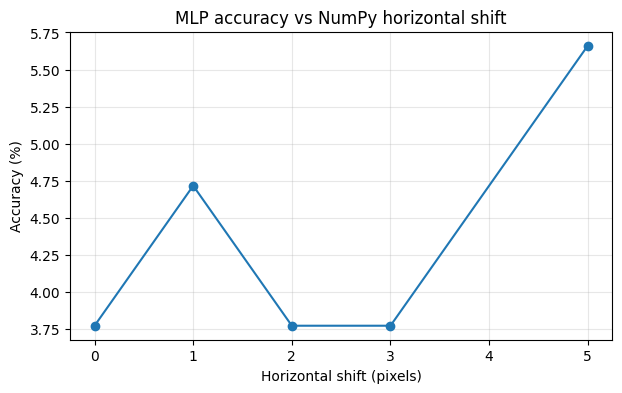

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(mlp_shift_df["dx"], mlp_shift_df["accuracy"] * 100, marker="o")
plt.title("MLP accuracy vs NumPy horizontal shift")
plt.xlabel("Horizontal shift (pixels)")
plt.ylabel("Accuracy (%)")
plt.grid(True, alpha=0.3)
plt.show()

## Convolution output-size formula

For a square input dimension, the convolution output size is:

\[
O = \left\lfloor\frac{N-F+2P}{S}\right\rfloor+1
\]

- `N`: input width/height
- `F`: filter/kernel width/height
- `P`: padding on each side
- `S`: stride
- `O`: output width/height

Example: `N=64`, `F=3`, `P=0`, `S=1` gives output size 62.

In [13]:
def conv_output_size(n, f, p=0, s=1):
    return ((n - f + 2*p) // s) + 1

examples = [
    (64, 3, 0, 1),
    (64, 3, 1, 1),
    (64, 3, 0, 2),
    (64, 5, 2, 1),
    (32, 3, 1, 2),
]
for n, f, p, s in examples:
    print(f"N={n}, F={f}, P={p}, S={s} -> O={conv_output_size(n,f,p,s)}")

N=64, F=3, P=0, S=1 -> O=62
N=64, F=3, P=1, S=1 -> O=64
N=64, F=3, P=0, S=2 -> O=31
N=64, F=5, P=2, S=1 -> O=64
N=32, F=3, P=1, S=2 -> O=16


In [14]:
def conv2d_scratch(image, kernel, stride=1, padding=0):
    image = np.asarray(image, dtype=np.float32)
    kernel = np.asarray(kernel, dtype=np.float32)
    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("image and kernel must both be 2D arrays")
    if stride < 1 or padding < 0:
        raise ValueError("stride must be >= 1 and padding must be >= 0")

    if padding:
        image = np.pad(image, ((padding, padding), (padding, padding)),
                       mode="constant", constant_values=0)

    h, w = image.shape
    kh, kw = kernel.shape
    out_h = (h - kh) // stride + 1
    out_w = (w - kw) // stride + 1
    if out_h <= 0 or out_w <= 0:
        raise ValueError("Kernel is larger than padded input")

    output = np.zeros((out_h, out_w), dtype=np.float32)
    for i in range(out_h):
        for j in range(out_w):
            patch = image[i*stride:i*stride+kh, j*stride:j*stride+kw]
            output[i, j] = np.sum(patch * kernel)
    return output

demo_img = np.arange(25, dtype=np.float32).reshape(5, 5)
mean_kernel = np.ones((3, 3), dtype=np.float32) / 9
print("Input shape:", demo_img.shape)
print("No padding, stride 1:", conv2d_scratch(demo_img, mean_kernel).shape)
print("Padding 1, stride 1:", conv2d_scratch(demo_img, mean_kernel, padding=1).shape)
print("No padding, stride 2:", conv2d_scratch(demo_img, mean_kernel, stride=2).shape)

Input shape: (5, 5)
No padding, stride 1: (3, 3)
Padding 1, stride 1: (5, 5)
No padding, stride 2: (2, 2)


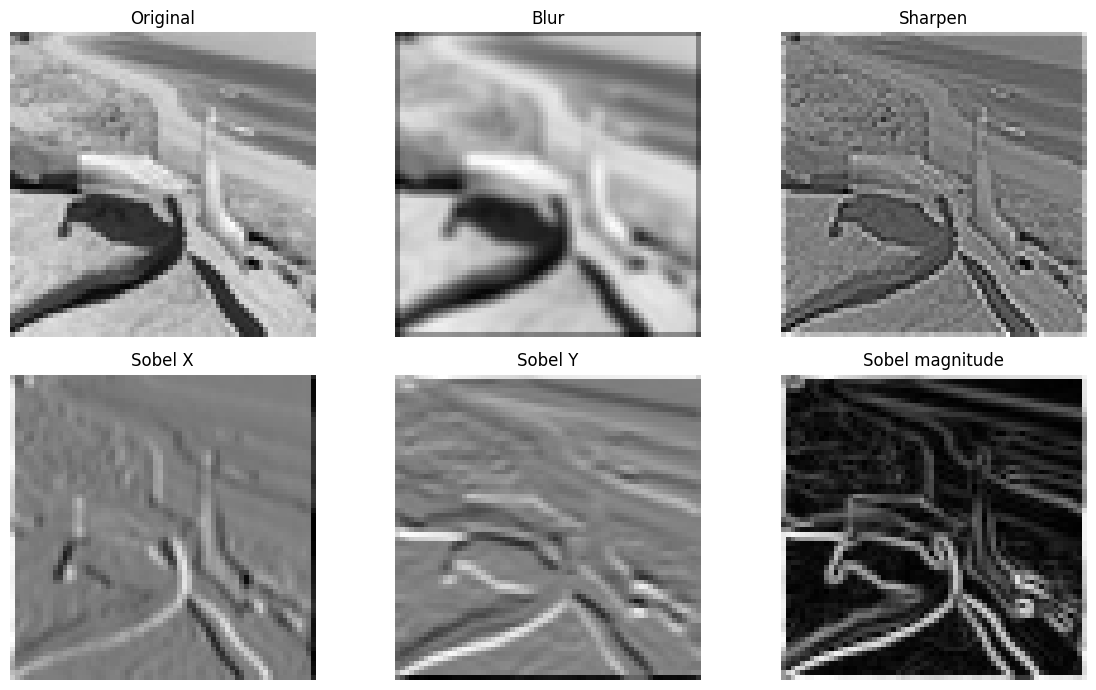

In [15]:
sample_idx = 0
sample_rgb = X_train[sample_idx]
sample_gray = cv2.cvtColor((sample_rgb * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY).astype(np.float32)

kernels = {
    "Blur": np.ones((3, 3), dtype=np.float32) / 9,
    "Sharpen": np.array([[0,-1,0],[-1,5,-1],[0,-1,0]], dtype=np.float32),
    "Sobel X": np.array([[-1,0,1],[-2,0,2],[-1,0,1]], dtype=np.float32),
    "Sobel Y": np.array([[-1,-2,-1],[0,0,0],[1,2,1]], dtype=np.float32),
}

filtered = {name: conv2d_scratch(sample_gray, k, padding=1) for name, k in kernels.items()}
gx, gy = filtered["Sobel X"], filtered["Sobel Y"]
edge_magnitude = np.sqrt(gx**2 + gy**2)

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
items = [("Original", sample_gray), *filtered.items(), ("Sobel magnitude", edge_magnitude)]
for ax, (title, img) in zip(axes.ravel(), items):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

##  CNN architecture



In [16]:
num_classes = len(class_names)

data_augmentation = keras.Sequential([
    layers.RandomTranslation(height_factor=0.06, width_factor=0.06, fill_mode="constant"),
    layers.RandomRotation(0.04, fill_mode="constant"),
    layers.RandomZoom(0.08, fill_mode="constant"),
    layers.RandomContrast(0.10),
], name="training_augmentation")

cnn = keras.Sequential([
    keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)),
    data_augmentation,
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.35),
    layers.Dense(num_classes, activation="softmax")
], name="ISL_CNN")

cnn.summary()

Model: "ISL_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ training_augmentation           │ (None, 64, 64, 3)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 23)             │         2,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,144,919 (4.37 MB)

 Trainable params: 1,144,919 (4.37 MB)

 Non-trainable params: 0 (0.00 B)

## Compile the CNN

In [17]:
cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## Train the CNN



In [18]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=8, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6
    )
]

EPOCHS = 40
BATCH_SIZE = 16

history_cnn = cnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step - accuracy: 0.0381 - loss: 3.1695 - val_accuracy: 0.0566 - val_loss: 3.1348 - learning_rate: 0.0010
Epoch 2/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 0.0600 - loss: 3.1284 - val_accuracy: 0.0377 - val_loss: 3.1348 - learning_rate: 0.0010
Epoch 3/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.0411 - loss: 3.1276 - val_accuracy: 0.0566 - val_loss: 3.1334 - learning_rate: 0.0010
Epoch 4/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.0253 - loss: 3.1276 - val_accuracy: 0.0377 - val_loss: 3.1403 - learning_rate: 0.0010
Epoch 5/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.0396 - loss: 3.1324 - val_accuracy: 0.0660 - val_loss: 3.1365 - learning_rate: 0.0010
Epoch 6/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - accuracy: 0.0631 - loss: 3.1212 - val_accuracy: 0.0849 - val_loss: 3.1708 - learning_rate: 0.0010
Epoch 7/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - accuracy: 0.0564 - loss: 3.0976 - val_acc

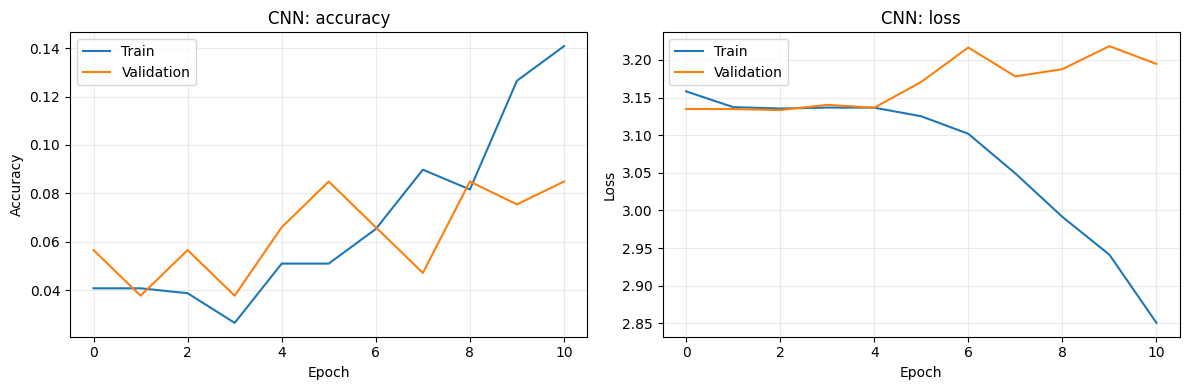

In [19]:
def plot_history(history, title):
    hist = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist["accuracy"], label="Train")
    axes[0].plot(hist["val_accuracy"], label="Validation")
    axes[0].set_title(f"{title}: accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].plot(hist["loss"], label="Train")
    axes[1].plot(hist["val_loss"], label="Validation")
    axes[1].set_title(f"{title}: loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

plot_history(history_cnn, "CNN")

In [20]:
cnn_test_loss, cnn_test_accuracy = cnn.evaluate(X_test, y_test, verbose=0)
cnn_prob = cnn.predict(X_test, verbose=0)
cnn_pred = np.argmax(cnn_prob, axis=1)

print(f"CNN test loss: {cnn_test_loss:.4f}")
print(f"CNN test accuracy: {cnn_test_accuracy*100:.2f}%")
print(classification_report(
    y_test, cnn_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

CNN test loss: 3.1354
CNN test accuracy: 5.66%
              precision    recall  f1-score   support

           A       0.00      0.00      0.00         4
           B       0.00      0.00      0.00         6
           C       0.00      0.00      0.00         5
           D       0.00      0.00      0.00         5
           E       0.06      0.43      0.10         7
           F       0.00      0.00      0.00         3
           G       0.00      0.00      0.00         4
           I       0.00      0.00      0.00         5
           K       0.00      0.00      0.00         5
           L       0.00      0.00      0.00         5
           M       0.00      0.00      0.00         4
           N       0.00      0.00      0.00         4
           O       0.00      0.00      0.00         6
           P       0.00      0.00      0.00         4
           Q       0.00      0.00      0.00         6
           R       0.07      0.75      0.13         4
           S       0.00      0.00 

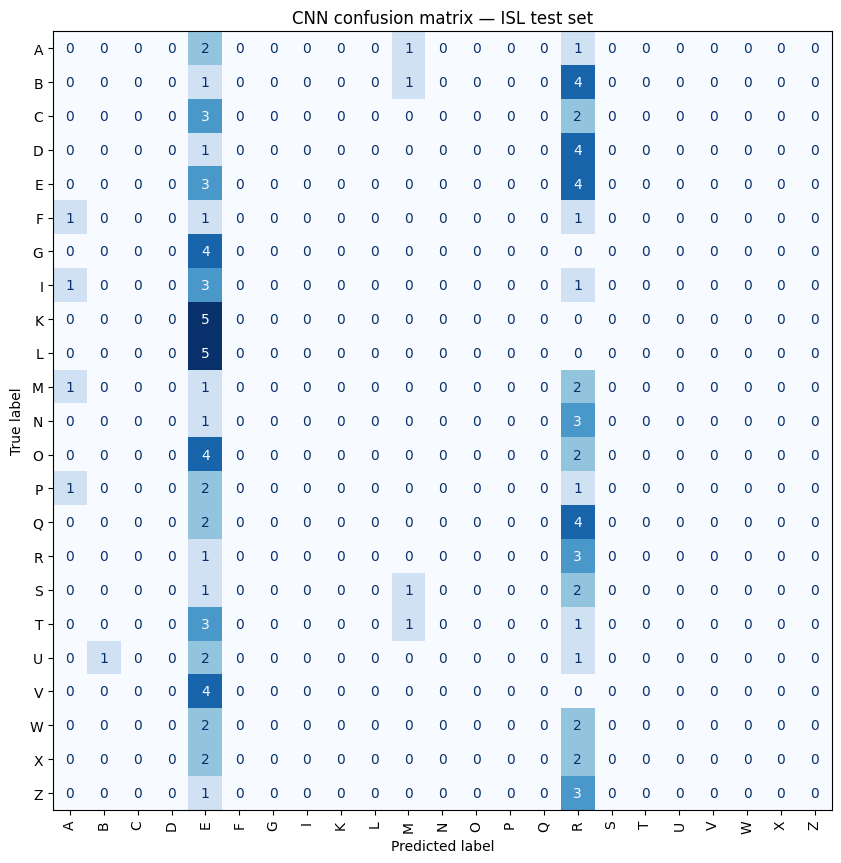

In [21]:
cm_cnn = confusion_matrix(y_test, cnn_pred, labels=list(range(num_classes)))
fig, ax = plt.subplots(figsize=(max(9, num_classes*0.45), max(7, num_classes*0.38)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_cnn, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=90, colorbar=False)
plt.title("CNN confusion matrix — ISL test set")
plt.tight_layout()
plt.show()

In [22]:
dnn = keras.Sequential([
    keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(num_classes, activation="softmax")
], name="ISL_DNN")

dnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
dnn.summary()

Model: "ISL_DNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     3,145,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 23)             │         2,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,181,847 (12.14 MB)

 Trainable params: 3,181,847 (12.14 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - accuracy: 0.0530 - loss: 6.4267 - val_accuracy: 0.0189 - val_loss: 3.1374 - learning_rate: 0.0010
Epoch 2/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 0.0395 - loss: 3.1399 - val_accuracy: 0.0472 - val_loss: 3.1320 - learning_rate: 0.0010
Epoch 3/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - accuracy: 0.0375 - loss: 3.1120 - val_accuracy: 0.0377 - val_loss: 3.1356 - learning_rate: 0.0010
Epoch 4/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.0509 - loss: 3.1217 - val_accuracy: 0.0472 - val_loss: 3.1357 - learning_rate: 0.0010
Epoch 5/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.0614 - loss: 3.0953 - val_accuracy: 0.0472 - val_loss: 3.1356 - learning_rate: 0.0010
Epoch 6/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - accuracy: 0.0472 - loss: 3.1007 - val_accuracy: 0.0472 - val_loss: 3.1357 - learning_rate: 0.0010
Epoch 7/40
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.0416 - loss: 3.1230 - val_acc

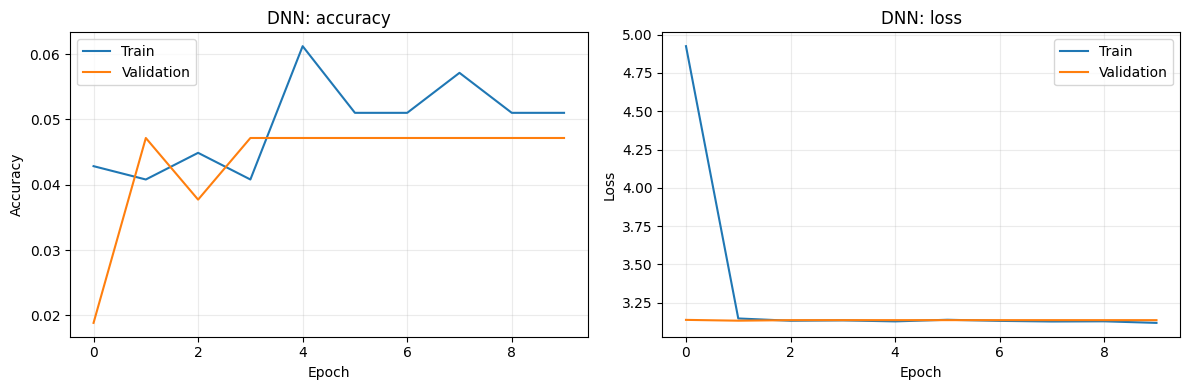

In [23]:
history_dnn = dnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=8, restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6
        )
    ],
    verbose=1
)
plot_history(history_dnn, "DNN")

## Evaluate DNN and compare CNN vs DNN on original test images

DNN test loss: 3.1342
DNN test accuracy: 4.72%


,model,test_accuracy_percent
0,MLP (sklearn),3.773585
1,CNN,5.660377
2,DNN,4.716981


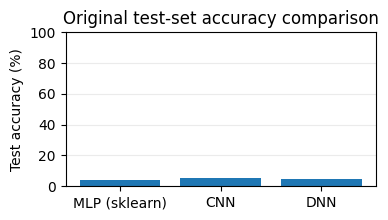

In [25]:
dnn_test_loss, dnn_test_accuracy = dnn.evaluate(X_test, y_test, verbose=0)
dnn_prob = dnn.predict(X_test, verbose=0)
dnn_pred = np.argmax(dnn_prob, axis=1)

print(f"DNN test loss: {dnn_test_loss:.4f}")
print(f"DNN test accuracy: {dnn_test_accuracy*100:.2f}%")

comparison = pd.DataFrame({
    "model": ["MLP (sklearn)", "CNN", "DNN"],
    "test_accuracy": [mlp_accuracy, cnn_test_accuracy, dnn_test_accuracy]
})
comparison["test_accuracy_percent"] = comparison["test_accuracy"] * 100
display(comparison[["model", "test_accuracy_percent"]])

plt.figure(figsize=(4, 2))
plt.bar(comparison["model"], comparison["test_accuracy_percent"])
plt.ylabel("Test accuracy (%)")
plt.title("Original test-set accuracy comparison")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.25)
plt.show()

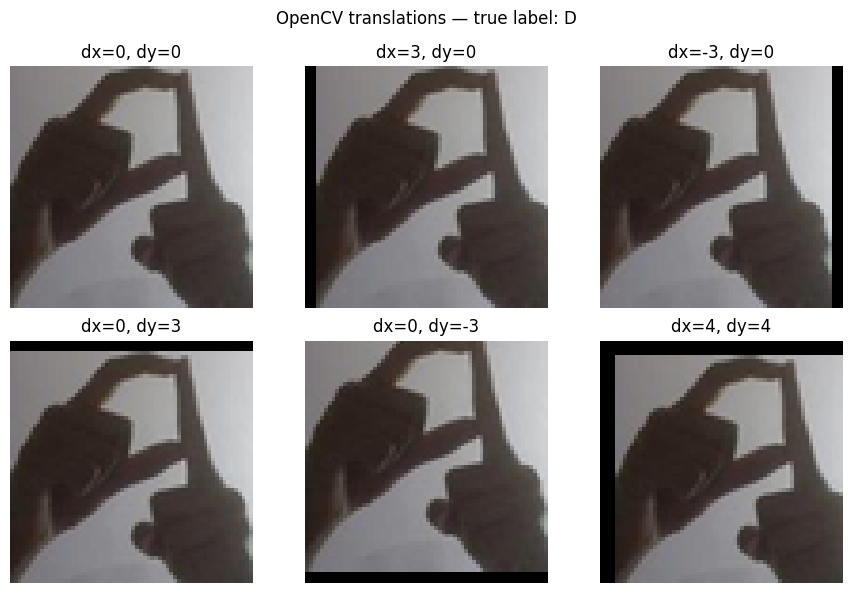

In [26]:
def shift_images_opencv(images, dx=0, dy=0):
    shifted_images = np.zeros_like(images, dtype=np.float32)
    matrix = np.float32([[1, 0, dx], [0, 1, dy]])
    for i, image in enumerate(images):
        # OpenCV expects width, height in dsize; image is RGB float [0,1].
        shifted_images[i] = cv2.warpAffine(
            image, matrix, (IMG_WIDTH, IMG_HEIGHT),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=(0, 0, 0)
        )
    return shifted_images

# Visualize one test image under translations.
sample = X_test[0]
shift_specs = [(0,0), (3,0), (-3,0), (0,3), (0,-3), (4,4)]
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for ax, (dx, dy) in zip(axes.ravel(), shift_specs):
    shifted = shift_images_opencv(sample[None, ...], dx=dx, dy=dy)[0]
    ax.imshow(shifted)
    ax.set_title(f"dx={dx}, dy={dy}")
    ax.axis("off")
plt.suptitle(f"OpenCV translations — true label: {index_to_class[int(y_test[0])]}")
plt.tight_layout()
plt.show()

## Evaluate CNN and DNN on multiple shifted test sets



In [27]:
shift_specs = [
    (0, 0), (1, 0), (2, 0), (3, 0), (5, 0),
    (-1, 0), (-2, 0), (-3, 0), (-5, 0),
    (0, 1), (0, 2), (0, 3), (0, 5),
    (0, -1), (0, -2), (0, -3), (0, -5),
    (3, 3), (-3, 3), (3, -3), (-3, -3)
]

shift_rows = []
for dx, dy in shift_specs:
    X_shift = shift_images_opencv(X_test, dx=dx, dy=dy)

    cnn_p = np.argmax(cnn.predict(X_shift, verbose=0), axis=1)
    dnn_p = np.argmax(dnn.predict(X_shift, verbose=0), axis=1)

    shift_rows.append({
        "dx": dx, "dy": dy,
        "shift": f"({dx:+d}, {dy:+d})",
        "CNN_accuracy": accuracy_score(y_test, cnn_p),
        "DNN_accuracy": accuracy_score(y_test, dnn_p)
    })

shift_results = pd.DataFrame(shift_rows)
display(shift_results)

,dx,dy,shift,CNN_accuracy,DNN_accuracy
0,0,0,"(+0, +0)",0.056604,0.047170
1,1,0,"(+1, +0)",0.056604,0.047170
2,2,0,"(+2, +0)",0.056604,0.056604
3,3,0,"(+3, +0)",0.056604,0.056604
4,5,0,"(+5, +0)",0.056604,0.056604
5,-1,0,"(-1, +0)",0.056604,0.047170
6,-2,0,"(-2, +0)",0.056604,0.047170
7,-3,0,"(-3, +0)",0.056604,0.047170
8,-5,0,"(-5, +0)",0.066038,0.047170
9,0,1,"(+0, +1)",0.075472,0.047170


## Plot accuracy versus image shift

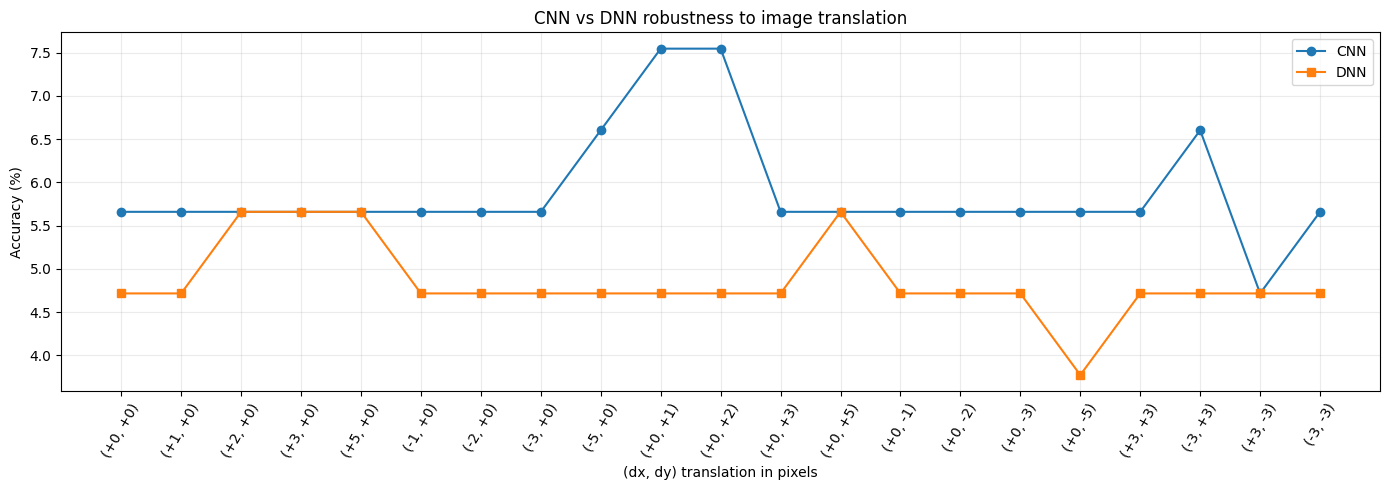

In [28]:
x = np.arange(len(shift_results))
plt.figure(figsize=(14, 5))
plt.plot(x, shift_results["CNN_accuracy"]*100, marker="o", label="CNN")
plt.plot(x, shift_results["DNN_accuracy"]*100, marker="s", label="DNN")
plt.xticks(x, shift_results["shift"], rotation=60)
plt.ylabel("Accuracy (%)")
plt.xlabel("(dx, dy) translation in pixels")
plt.title("CNN vs DNN robustness to image translation")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [29]:
base_cnn = float(shift_results.loc[
    (shift_results.dx == 0) & (shift_results.dy == 0), "CNN_accuracy"
].iloc[0])
base_dnn = float(shift_results.loc[
    (shift_results.dx == 0) & (shift_results.dy == 0), "DNN_accuracy"
].iloc[0])

shift_results["CNN_drop_pp"] = (base_cnn - shift_results["CNN_accuracy"]) * 100
shift_results["DNN_drop_pp"] = (base_dnn - shift_results["DNN_accuracy"]) * 100
display(shift_results[[
    "shift", "CNN_accuracy", "CNN_drop_pp", "DNN_accuracy", "DNN_drop_pp"
]])

,shift,CNN_accuracy,CNN_drop_pp,DNN_accuracy,DNN_drop_pp
0,"(+0, +0)",0.056604,0.000000,0.047170,0.000000
1,"(+1, +0)",0.056604,0.000000,0.047170,0.000000
2,"(+2, +0)",0.056604,0.000000,0.056604,-0.943396
3,"(+3, +0)",0.056604,0.000000,0.056604,-0.943396
4,"(+5, +0)",0.056604,0.000000,0.056604,-0.943396
5,"(-1, +0)",0.056604,0.000000,0.047170,0.000000
6,"(-2, +0)",0.056604,0.000000,0.047170,0.000000
7,"(-3, +0)",0.056604,0.000000,0.047170,0.000000
8,"(-5, +0)",0.066038,-0.943396,0.047170,0.000000
9,"(+0, +1)",0.075472,-1.886792,0.047170,0.000000


In [30]:
cm = confusion_matrix(y_test, cnn_pred, labels=list(range(num_classes)))
confusions = []
for true_idx in range(num_classes):
    for pred_idx in range(num_classes):
        if true_idx != pred_idx and cm[true_idx, pred_idx] > 0:
            confusions.append({
                "actual": index_to_class[true_idx],
                "predicted": index_to_class[pred_idx],
                "count": int(cm[true_idx, pred_idx])
            })

confusion_df = pd.DataFrame(confusions)
if len(confusion_df):
    display(confusion_df.sort_values("count", ascending=False).head(15))
else:
    print("No off-diagonal CNN errors in this test split.")

,actual,predicted,count
18,K,E,5
19,L,E,5
14,G,E,4
10,E,R,4
42,V,E,4
25,O,E,4
31,Q,R,4
9,D,R,4
5,B,R,4
48,Z,R,3


##  Predict the alphabet for one image

Choose an image from the test split. The model returns a probability for each class. The class with the highest probability is the predicted alphabet.

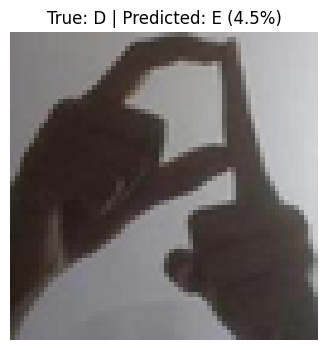

,alphabet,probability
0,E,0.044928
1,R,0.044411
2,M,0.044331
3,F,0.044181
4,B,0.044125


In [31]:
example_index = 0
image = X_test[example_index]
true_label = index_to_class[int(y_test[example_index])]

probabilities = cnn.predict(image[None, ...], verbose=0)[0]
predicted_index = int(np.argmax(probabilities))
predicted_label = index_to_class[predicted_index]
confidence = float(probabilities[predicted_index])

plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title(f"True: {true_label} | Predicted: {predicted_label} ({confidence*100:.1f}%)")
plt.axis("off")
plt.show()

top_indices = np.argsort(probabilities)[::-1][:5]
display(pd.DataFrame({
    "alphabet": [index_to_class[i] for i in top_indices],
    "probability": [probabilities[i] for i in top_indices]
}))

## Save the trained models and class mapping

The Keras models are saved in `.keras` format. The class mapping is saved as JSON so a future prediction script uses exactly the same output-index-to-alphabet mapping.

Keep the model and mapping together.

In [32]:
OUTPUT_DIR = Path("isl_model_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

cnn.save(OUTPUT_DIR / "isl_cnn.keras")
dnn.save(OUTPUT_DIR / "isl_dnn.keras")

with open(OUTPUT_DIR / "class_mapping.json", "w", encoding="utf-8") as f:
    json.dump(
        {"class_to_index": class_to_index, "index_to_class": {
            str(k): v for k, v in index_to_class.items()
        }, "image_size": [IMG_HEIGHT, IMG_WIDTH], "channels": CHANNELS},
        f, indent=2
    )

shift_results.to_csv(OUTPUT_DIR / "shift_robustness_results.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "model_accuracy_comparison.csv", index=False)

print("Saved outputs to:", OUTPUT_DIR.resolve())

Saved outputs to: C:\Users\Dell\Downloads\CNN practice\isl_model_outputs
